<a href="https://colab.research.google.com/github/Anna-Mengxuan-Zhang/CFM-MNIST/blob/main/cfm_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class Conv3(nn.Module):
    def __init__(
        self, in_channels: int, out_channels: int, is_res: bool = False
    ) -> None:
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(),
        )
        self.conv = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 3, 1, 1),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(),
        )

        self.is_res = is_res

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.main(x)
        if self.is_res:
            x = x + self.conv(x)
            return x / 1.414
        else:
            return self.conv(x)


class UnetDown(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super(UnetDown, self).__init__()
        layers = [Conv3(in_channels, out_channels), nn.MaxPool2d(2)]
        self.model = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        return self.model(x)


class UnetUp(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super(UnetUp, self).__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, 2, 2),
            Conv3(out_channels, out_channels),
            Conv3(out_channels, out_channels),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = torch.cat((x, skip), 1)
        x = self.model(x)

        return x


class TimeSiren(nn.Module):
    def __init__(self, emb_dim: int) -> None:
        super(TimeSiren, self).__init__()

        self.lin1 = nn.Linear(1, emb_dim, bias=False)
        self.lin2 = nn.Linear(emb_dim, emb_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(-1, 1)
        x = torch.sin(self.lin1(x))
        x = self.lin2(x)
        return x


class NaiveUnet(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, n_feat: int = 64) -> None:
        super(NaiveUnet, self).__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels

        self.n_feat = n_feat

        self.init_conv = Conv3(in_channels, n_feat, is_res=True)

        self.down1 = UnetDown(n_feat, n_feat)
        self.down2 = UnetDown(n_feat, 2 * n_feat)
        self.down3 = UnetDown(2 * n_feat, 2 * n_feat)

        self.to_vec = nn.Sequential(nn.AvgPool2d(4), nn.ReLU())

        self.timeembed = TimeSiren(2 * n_feat)

        self.up0 = nn.Sequential(
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat,4,4),
            nn.GroupNorm(8, 2 * n_feat),
            nn.ReLU(),
        )

        self.up1 = UnetUp(4 * n_feat, 2*n_feat)
        self.up2 = UnetUp(4 * n_feat, n_feat)
        self.up3 = UnetUp(2 * n_feat, n_feat)
        self.out = nn.Conv2d(2 * n_feat, self.out_channels, 3, 1, 1)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:

        x = self.init_conv(x)

        down1 = self.down1(x)
        down2 = self.down2(down1)
        down3 = self.down3(down2)

        thro = self.to_vec(down3)
        temb = self.timeembed(t).view(-1, self.n_feat * 2, 1, 1)

        thro = self.up0(thro + temb)

        up1 = self.up1(thro, down3)
        up2 = self.up2(up1, down2)
        up3 = self.up3(up2, down1)

        out = self.out(torch.cat((up3, x), 1))

        return out


Using device: cuda


100%|██████████| 938/938 [01:27<00:00, 10.78it/s]


epoch 1, avg loss: 0.1372


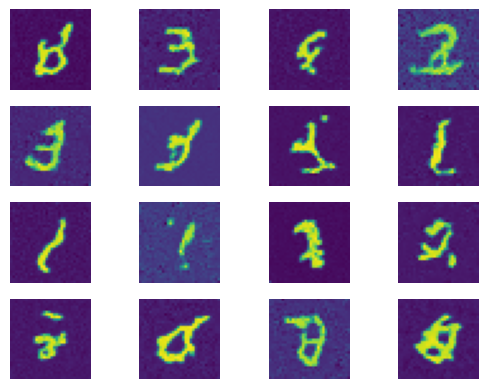

100%|██████████| 938/938 [01:27<00:00, 10.78it/s]


epoch 2, avg loss: 0.0886


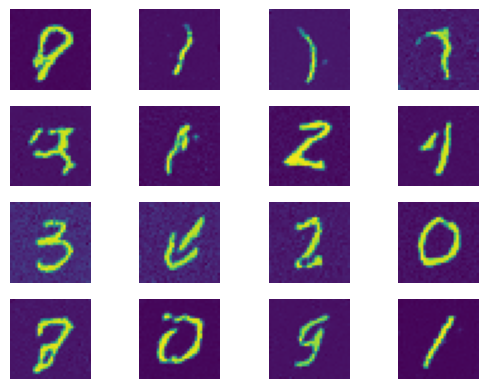

100%|██████████| 938/938 [01:27<00:00, 10.72it/s]


epoch 3, avg loss: 0.0816


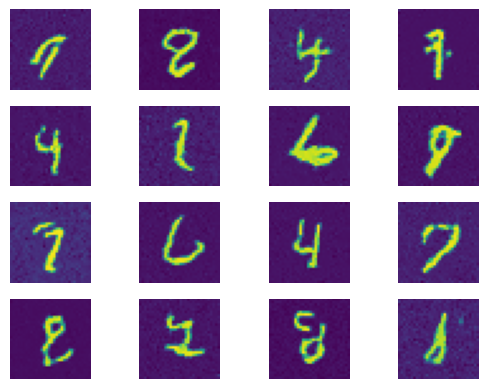

100%|██████████| 938/938 [01:27<00:00, 10.76it/s]


epoch 4, avg loss: 0.0790


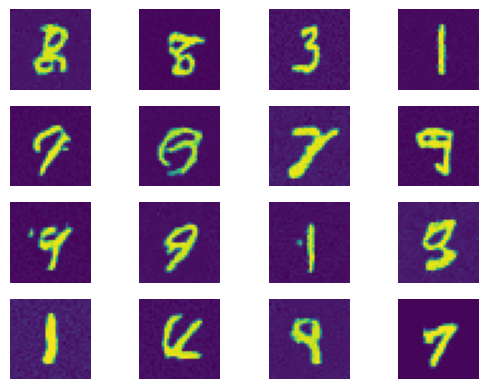

100%|██████████| 938/938 [01:28<00:00, 10.65it/s]


epoch 5, avg loss: 0.0767


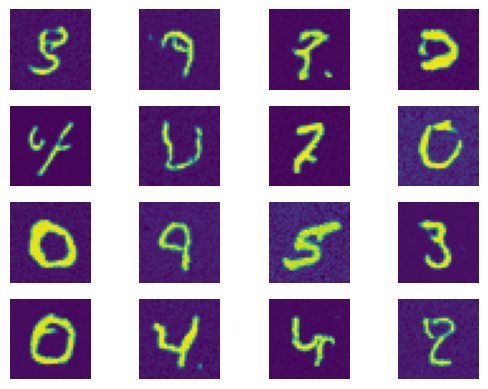

100%|██████████| 938/938 [01:28<00:00, 10.60it/s]


epoch 6, avg loss: 0.0754


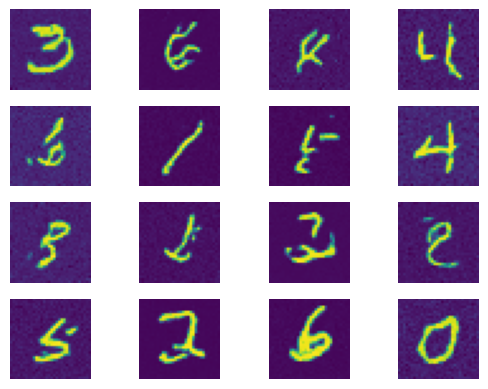

100%|██████████| 938/938 [01:28<00:00, 10.57it/s]


epoch 7, avg loss: 0.0741


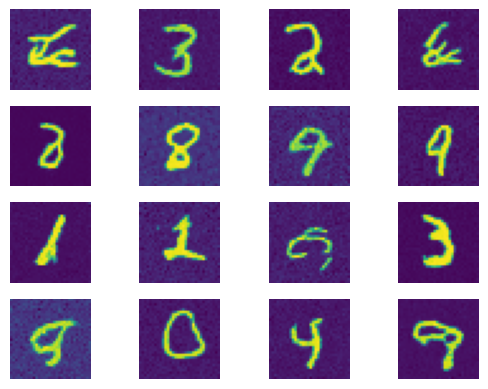

100%|██████████| 938/938 [01:28<00:00, 10.57it/s]


epoch 8, avg loss: 0.0735


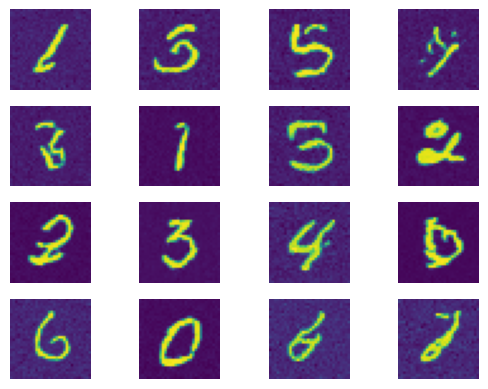

100%|██████████| 938/938 [01:28<00:00, 10.58it/s]


epoch 9, avg loss: 0.0727


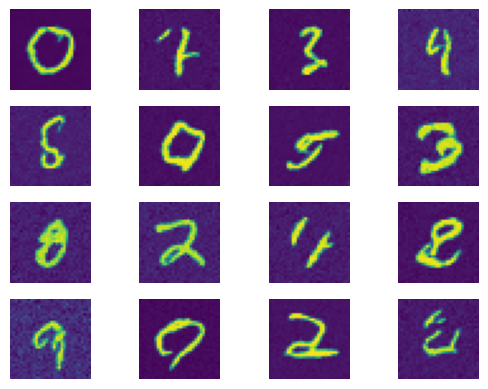

100%|██████████| 938/938 [01:28<00:00, 10.57it/s]


epoch 10, avg loss: 0.0720


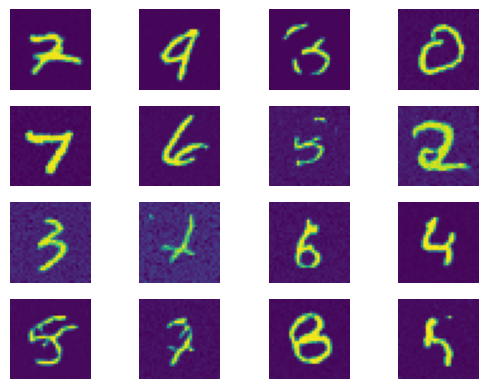

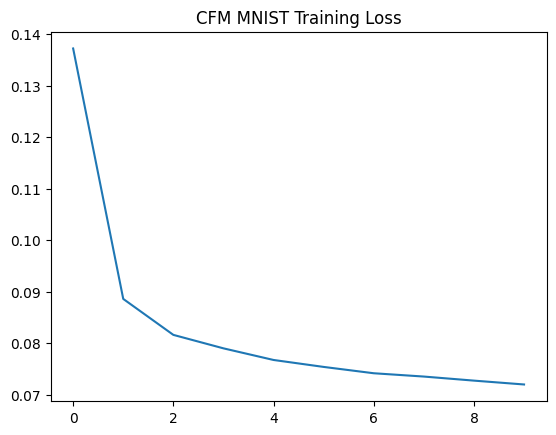

In [8]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

tf = transforms.Compose(
    [transforms.Pad(padding = 2, fill = 0), transforms.ToTensor(), transforms.Normalize((0.5,),(1,))]
    )
dataset = datasets.MNIST('./data', train = True, download = True, transform = tf)
dataloader = DataLoader(dataset, batch_size = 64, shuffle = True)
model = NaiveUnet(1, 1).to(device)
optim = optim.Adam(model.parameters(), lr = 2e-4)

model.train()
n_epochs = 10
loss_history = []

for epoch in range(n_epochs):
  total_loss = 0
  pbar = tqdm(dataloader)
  for x,_ in pbar:
    optim.zero_grad()
    x = x.to(device)
    B = x.shape[0]
    x0 = torch.randn_like(x).to(device)
    t = torch.rand(B, device = device).view(B, 1, 1, 1)
    xt = (1 - t) * x0 + t * x
    v_tar = x - x0
    v_pred = model(xt, t)
    loss = torch.mean((v_tar - v_pred) ** 2)
    loss.backward()
    optim.step()

    total_loss += loss.item()
  avg_loss = total_loss / len(dataloader)
  loss_history.append(avg_loss)
  print(f'epoch {epoch + 1}, avg loss: {avg_loss:.4f}')

  n_sample = 16
  n_steps = 20
  model.eval()
  with torch.no_grad():
    x = torch.randn(n_sample, 1, 32, 32).to(device)
    dt = 1 / n_steps
    for i in range(n_steps):
      current_t = torch.full((n_sample,), i * dt, device = device)
      v = model(x, current_t)
      x = x + v * dt
    x = torch.clamp(x, -1, 1)
    x = (x.cpu() + 1) / 2
  for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x[i, 0])
    plt.axis('off')
  plt.show()

plt.plot(loss_history)
plt.title('CFM MNIST Training Loss')
plt.show()



